In [4]:
print(10)

10


In [37]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde

# custom helper scripts
#from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

In [38]:
'''
This notebook implements an optical depth calculation for the
WR population. Similar to Pauli+22 (https://ui.adsabs.harvard.edu/abs/2022A&A...667A..58P)
'''

from posydon.utils.common_functions import convert_metallicity_to_string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from posydon.config import PATH_TO_POSYDON
from tqdm import tqdm
from posydon.popsyn.synthetic_population import Population
import pickle



def optical_depth_calc(Mdot, R, v_inf, kappa,  v0=20):
    '''
    Optical depth calculation following Langer 1989
    https://ui.adsabs.harvard.edu/abs/1989A%26A...210...93L/abstract
    
    tau = - (kappa * Mdot)/(4 * pi * R * (v_inf-v_0) ln (v_inf/v_0))
    
    where kappa is the opacity, Mdot the mass loss rate, v_inf the terminal wind velocity, and v0 the expansion velocity at the base of the wind.
    
    Parameters
    ----------
    Mdot : float or np.array
        Mass loss rate in Msun/yr
    R : float or np.array
        Stellar radius in Rsun
    v_inf : float or np.array
        Terminal wind velocity in km/s
    kappa : float or np.array
        Opacity in cm^2/g
    v0 : float, optional
        Expansion velocity at the base of the wind in km/s, by default 20 km/s
        
    Returns
    -------
    tau : float or np.array
        Optical depth
    '''
    
    Mdot_cgs = Mdot * 1.989e33 / (365.25*24*3600)  # convert Msun/yr to g/s
    R_cgs = R * 6.955e10  # convert Rsun to cm
    v_inf_cgs = v_inf * 1e5  # convert km/s to cm/s
    v0_cgs = v0 * 1e5  # convert km/s to cm/s
    
    tau = (kappa * Mdot_cgs) / (4 * np.pi * R_cgs * (v_inf_cgs - v0_cgs)) * np.log(v_inf_cgs / v0_cgs)
    
    return  tau
    
    
def escape_velocity(mass, radius, eddington_factor):
    '''
    The esscape velocity from the stellar surface.
    
    Parameters
    ----------
    mass : float or np.array
        Stellar mass in Msun
    radius : float or np.array
        Stellar radius in Rsun
    eddington_factor : float or np.array
        Eddington factor (dimensionless)
    
    Returns
    -------
    v_esc : float or np.array
        Escape velocity in km/s
    '''
    
    G_cgs = 6.67430e-8  # gravitational constant in cm^3 g^-1 s^-2
    mass_cgs = mass * 1.989e33  # convert Msun to g
    radius_cgs = radius * 6.955e10  # convert Rsun to cm
    
    v_esc = np.sqrt(2 * G_cgs * mass_cgs * (1 - eddington_factor) / radius_cgs)  # in cm/s
    v_esc_kms = v_esc / 1e5  # convert to km/s
    
    return v_esc_kms
    
    

def terminal_wind_velocity(v_esc, Teff, surface_H, surface_He):
    '''
       Terminal wind velocity as a function of the escape velocity.
    Sort of following Pauli+22, we set different factors based on the effective temperature and surface hydrogen content.
    
    WC stars (no helium envelope):              factor = 1.6
    (H-rich, H-poor, H-free) WN stars:          factor = 1.3
    Hot OB stars (27 500 K ≤ Teff ≤ 50 000 K):  factor = 2.6
    Cool OB stars (12 500 K ≤ Teff ≤ 22 500 K): factor = 1.3
    Supergiants (Teff < 10 000 K):              factor = 0.7

    
    Parameters
    ----------
    v_esc : float or np.array
        Escape velocity in km/s
    Teff : float or np.array
        Effective temperature in K
    surface_H : float or np.array
        Surface hydrogen mass fraction
    surface_He : float or np.array
        Surface helium mass fraction
        
    Returns
    -------
    v_inf : float or np.array
        Terminal wind velocity in km/s
    '''
    # Convert inputs to arrays for vectorization
    v_esc = np.atleast_1d(v_esc)
    Teff = np.atleast_1d(Teff)
    surface_H = np.atleast_1d(surface_H)
    surface_He = np.atleast_1d(surface_He)
    
    # Initialize factor array with default value
    factor = np.full_like(v_esc, 1.3, dtype=float)
    
    # H-rich stars (surface_H > 0.4)
    h_rich_mask = surface_H > 0.4
    
    # Hot OB stars
    hot_ob_mask = h_rich_mask & (Teff >= 27500) & (Teff <= 50000)
    factor[hot_ob_mask] = 2.6
    
    # Cool OB stars
    cool_ob_mask = h_rich_mask & (Teff >= 12500) & (Teff <= 22500)
    factor[cool_ob_mask] = 1.3
    
    # Supergiants
    supergiant_mask = h_rich_mask & (Teff < 10000)
    factor[supergiant_mask] = 0.7
    
    # H-poor or H-free stars (surface_H <= 0.4)
    h_poor_mask = ~h_rich_mask
    
    # WC stars
    wc_mask = h_poor_mask & (surface_He <= 0.7) & (surface_H < 0.1)
    factor[wc_mask] = 1.6
    
    v_inf = factor * v_esc
    
    # Return scalar if input was scalar
    if v_inf.size == 1:
        return float(v_inf[0])
    
    return v_inf
    
def eddington_factor(kappa, luminosity, mass):
    '''
    
    Eddington factor calculation.
    
    Parameters
    ----------
    kappa : float or np.array
        Opacity in cm^2/g
    luminosity : float or np.array
        Stellar luminosity in Lsun
    mass : float or np.array
        Stellar mass in Msun
    
    
    Returns
    -------
    gamma : float or np.array
        Eddington factor (dimensionless)
    '''
    
    L_cgs = luminosity * 3.828e33  # convert Lsun to erg/s
    M_cgs = mass * 1.989e33  # convert Msun to g
    c_cgs = 2.99792458e10  # speed of light in cm/s
    G_cgs = 6.67430e-8  # gravitational constant in cm^3 g^-1 s^-2
    gamma = (kappa * L_cgs) / (4 * np.pi * G_cgs * M_cgs * c_cgs)
    
    return gamma
    
    
def optical_depth_calculation(M, R, L, Mdot, surface_H, surface_He, Teff):
    '''
    Optical depth calculation given stellar parameters.
    
    Assumptions:
    - expansion velocity at the base of the wind v_0 = 20 km/s
    - terminal wind velocity v_inf = 1.3 * v_esc (following Gräfener et al. 2011)
    
    Parameters
    ----------
    M : float or np.array
        Stellar mass in Msun
    R : float or np.array
        Stellar radius in Rsun
    L : float or np.array
        Stellar luminosity in Lsun
    Mdot : float or np.array
        Mass loss rate in Msun/yr
        
    Returns
    -------
    tau : float or np.array
        Optical depth
    '''
    # Assumptions:
    v_0 = 20  # km/s, expansion velocity at the base of the wind
    
    # Opacity
    kappa = 0.2 * (1 + surface_H)  # cm^2/g
    
    # Eddington factor
    gamma = eddington_factor(kappa, L, M)

    # Escape velocity
    v_esc = escape_velocity(M, R, gamma)
    
    # Terminal wind velocity
    # adaptive factor based on types
    v_inf = terminal_wind_velocity(v_esc, Teff, surface_H, surface_He)

    # Optical depth
    tau = optical_depth_calc(Mdot, R, v_inf, kappa,  v_0)
    
    return tau



In [39]:
def calc_Teff(L, R):
    """Calculate the effective temperature.
    
    L : np.array
        Logarithmic luminosity in L_sun
    R : np.array
        Logarithmic radius in R_sun
    Returns
    -------
    Teff : np.array
        Logarithmic effective temperature in K
    """
    L_vals = 10**L * 3.828e26  # L_sun to Watts
    R_vals = 10**R* 6.957e8   # R_sun to meters
    sigma = 5.67037442e-8
    Teff_vals = (L_vals / (4 * np.pi * R_vals**2 * sigma))**0.25
    
    return np.log10(Teff_vals)

In [12]:
from posydon.grids.psygrid import PSyGrid
from posydon.config import PATH_TO_POSYDON_DATA
grid_path = '/srv/astro/projects/posydon/running_grids/POSYDON_GRIDS_v2/HMS-HMS/1e+00_Zsun/ORIGINAL/grid_low_res_ext_combined_rerun8C_dedt_hepulse.h5'

grid = PSyGrid(grid_path)


In [40]:
import numpy as np

mask_m1 = np.isclose(grid.initial_values['star_1_mass'], 90, atol=1)
print(np.sum(mask_m1))
mask_q = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], 0.85, atol=0.025)
print(np.sum(mask_q & mask_m1))
mask_P = np.isclose(grid.initial_values['period_days'], 5, atol=0.5)
print(np.sum(mask_P & mask_q & mask_m1))

example_index = np.where(mask_P & mask_q & mask_m1)[0][0]

680
34
1


680
34
1


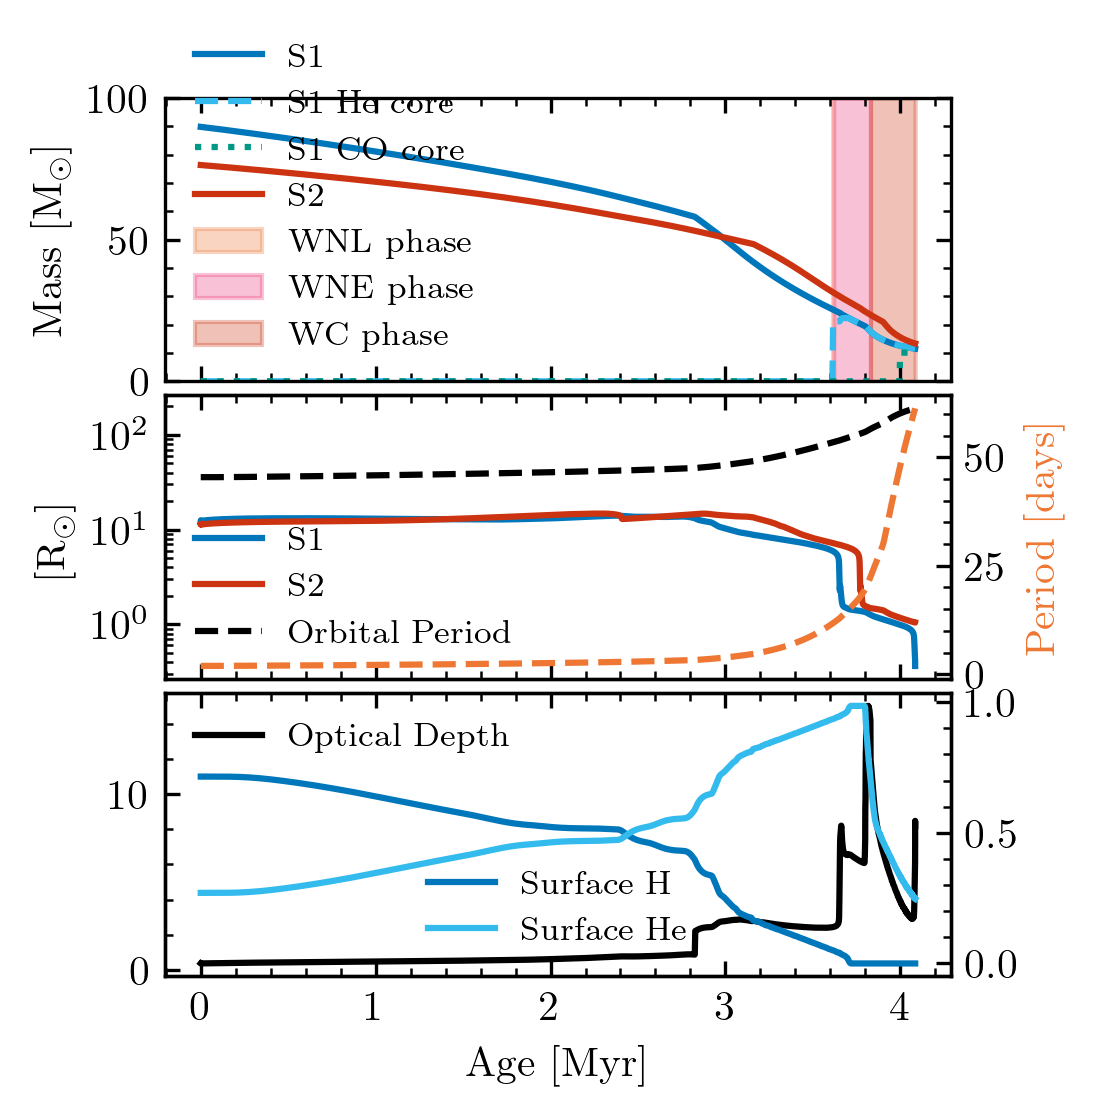

11.524701474301326
WNL duration: 0.00 Myr
WNE duration: 0.21 Myr
WC duration: 0.25 Myr
[3.82994897 3.8307346  3.8314549  3.83214509 3.83282136 3.8334915
 3.83415926 3.83482631 3.83562678 3.8365767  3.83737513 3.83810797
 3.83881054 3.83949907 3.84018134 3.84086113 3.84154032 3.84235535
 3.84332364 3.84413746 3.84488453 3.845601   3.84630341 3.84699958
 3.84769336 3.8483867  3.84921872 3.85020173 3.85103054 3.85179254
 3.85252397 3.85324134 3.85395254 3.85466152 3.85551229 3.85652086
 3.85736869 3.85814723 3.85889414 3.85962666 3.860353   3.86107716
 3.86194616 3.86296789 3.86383098 3.8646255  3.86538858 3.8661374
 3.8668802  3.86762097 3.8685099  3.86955072 3.87043207 3.87124441
 3.87202534 3.87279221 3.87355331 3.87431267 3.87522391 3.87629432
 3.87720003 3.87803472 3.87883714 3.87962522 3.8804076  3.88118841
 3.88212539 3.88322733 3.88415933 3.88501821 3.88584418 3.88665575
 3.88746171 3.88826631 3.88923184 3.89035045 3.89130466 3.8921881
 3.89303978 3.89387772 3.89471058 3.89571001 

In [41]:

mask_m1 = np.isclose(grid.initial_values['star_1_mass'], 90, atol=1)
print(np.sum(mask_m1))
mask_q = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], 0.85, atol=0.025)
print(np.sum(mask_q & mask_m1))
mask_P = np.isclose(grid.initial_values['period_days'], 2, atol=0.5)
print(np.sum(mask_P & mask_q & mask_m1))

example_index = np.where(mask_P & mask_q & mask_m1)[0][0]
model = grid[example_index]

fig, ax = plt.subplots(3, 1, figsize=(3.38, 2.535*1.5), sharex=True)

x_axis = model.binary_history['age'] / 1e6  # Convert age to Myr

ax[0].plot(x_axis, model.binary_history['star_1_mass'],
           label='S1', color=tol_vibrant[0])
ax[0].plot(x_axis, model.history1['he_core_mass'], label='S1 He core', color=tol_vibrant[1], linestyle='--')
ax[0].plot(x_axis, model.history1['co_core_mass'], label='S1 CO core', color=tol_vibrant[2], linestyle=':')
ax[0].plot(x_axis, model.binary_history['star_2_mass'],
           label='S2', color=tol_vibrant[4])

ax1 = ax[1].twinx()
ax1.set_ylabel('Period [days]', color=tol_vibrant[3])
ax1.plot(x_axis, model.binary_history['period_days'], label='Orbital Period', color=tol_vibrant[3], linestyle='--')

ax[1].plot(x_axis, 10**model.history1['log_R'], label='S1',
           color=tol_vibrant[0])
ax[1].plot(x_axis, 10**model.history2['log_R'], label='S2', color=tol_vibrant[4])
ax[1].plot(x_axis, model.binary_history['binary_separation'], label='Orbital Period', color='black', linestyle='--')
ax[1].set_yscale('log')



# check when WNL, WNE, WC phases occur based on surface abundances and optical depth
surface_H = model.history1['surface_h1']
surface_He = model.history1['surface_he4']
optical_depth = optical_depth_calculation(model.binary_history['star_1_mass'], 10**model.history1['log_R'], 10**model.history1['log_L'], 10**model.binary_history['lg_wind_mdot_1'], surface_H, surface_He, Teff=10**calc_Teff(model.history1['log_L'], model.history1['log_R']))


# WNL phase: surface H > 0.05, optical depth > 0.5
# not H burning
WNL_mask = (surface_H > 0.05) & (optical_depth > 0.5) & (model.history1['center_h1'] < 0.01)
if np.any(WNL_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNL_mask, color=tol_vibrant[3], alpha=0.3, label='WNL phase')
WNE_mask = (surface_H <= 0.05) & (surface_He >= 0.7) & (optical_depth > 1.5)
if np.any(WNE_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNE_mask, color=tol_vibrant[5], alpha=0.3, label='WNE phase')
WC_mask = (surface_H <= 0.05) & (surface_He < 0.7) & (optical_depth > 1.5)
if np.any(WC_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WC_mask, color=tol_vibrant[4], alpha=0.3, label='WC phase')

# twin y-axis for optical depth and abundances
ax2 = ax[2].twinx()
ax[2].plot(x_axis, optical_depth, label='Optical Depth', color='black')

ax2.plot(x_axis, surface_H, label='Surface H', color=tol_vibrant[0])
ax2.plot(x_axis, surface_He, label='Surface He', color=tol_vibrant[1])
ax2.legend()
ax[2].legend()

plt.subplots_adjust(hspace=0.05)

#ax[0].set_xticklabels([])
ax[0].set_ylim(0, 100)

ax[0].legend()
ax[0].set_ylabel('Mass [M$_\odot$]')
ax[1].legend()
ax[1].set_ylabel('[R$_\odot$]')
ax[-1].set_xlabel('Age [Myr]')

plt.show()

print(model.final_values['star_1_mass'])
print(f'WNL duration: {np.sum(np.diff(x_axis[WNL_mask])):.2f} Myr')
print(f'WNE duration: {np.sum(np.diff(x_axis[WNE_mask])):.2f} Myr')
print(f'WC duration: {np.sum(np.diff(x_axis[WC_mask])):.2f} Myr')

print(x_axis[WC_mask])


680
34
1


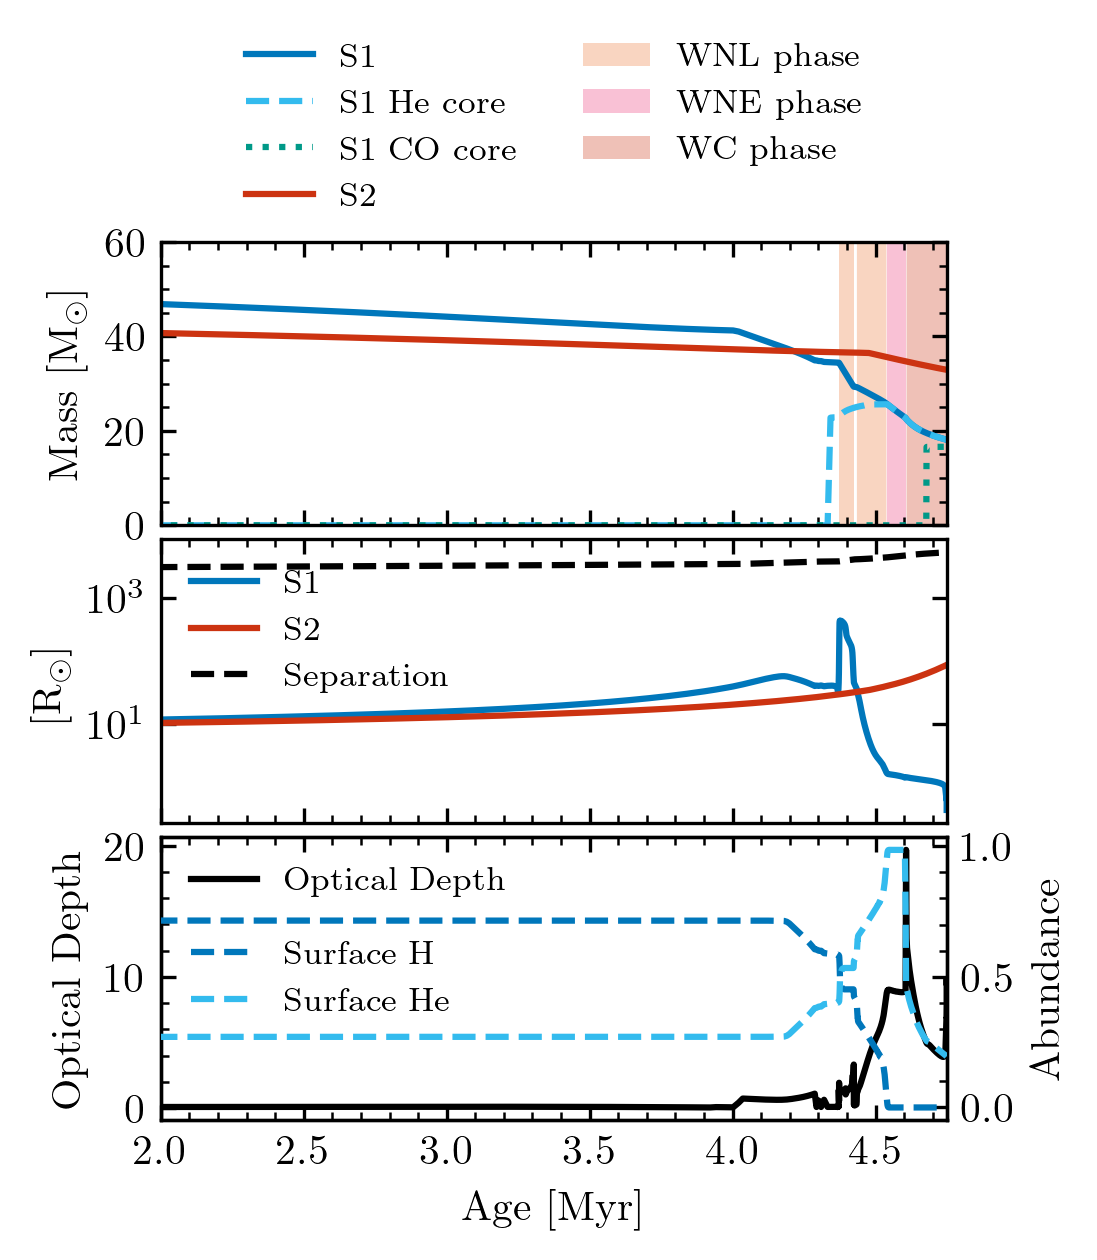

18.111970287897066
WNL duration: 0.17 Myr
WNE duration: 0.07 Myr
WC duration: 0.14 Myr


In [68]:
import numpy as np

mask_m1 = np.isclose(grid.initial_values['star_1_mass'], 50, atol=1)
print(np.sum(mask_m1))
mask_q = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], 0.85, atol=0.025)
print(np.sum(mask_q & mask_m1))
mask_P = np.isclose(grid.initial_values['period_days'], 2e3, rtol=0.1)
print(np.sum(mask_P & mask_q & mask_m1))

example_index = np.where(mask_P & mask_q & mask_m1)[0][0]
model = grid[example_index]

fig, ax = plt.subplots(3, 1, figsize=(3.38, 2.535*1.5), sharex=True)

x_axis = model.binary_history['age'] / 1e6  # Convert age to Myr

ax[0].plot(x_axis, model.binary_history['star_1_mass'],
           label='S1', color=tol_vibrant[0])
ax[0].plot(x_axis, model.history1['he_core_mass'], label='S1 He core', color=tol_vibrant[1], linestyle='--')
ax[0].plot(x_axis, model.history1['co_core_mass'], label='S1 CO core', color=tol_vibrant[2], linestyle=':')
ax[0].plot(x_axis, model.binary_history['star_2_mass'],
           label='S2', color=tol_vibrant[4])

ax[1].plot(x_axis, 10**model.history1['log_R'], label='S1',
           color=tol_vibrant[0])
ax[1].plot(x_axis, 10**model.history2['log_R'], label='S2', color=tol_vibrant[4])
ax[1].plot(x_axis, model.binary_history['binary_separation'], label='Separation', color='black', linestyle='--')
ax[1].set_yscale('log')

# check when WNL, WNE, WC phases occur based on surface abundances and optical depth
surface_H = model.history1['surface_h1']
surface_He = model.history1['surface_he4']
optical_depth = optical_depth_calculation(model.binary_history['star_1_mass'], 10**model.history1['log_R'], 10**model.history1['log_L'], 10**model.binary_history['lg_wind_mdot_1'], surface_H, surface_He, Teff=10**calc_Teff(model.history1['log_L'], model.history1['log_R']))


# WNL phase: surface H > 0.05, optical depth > 0.5
# not H burning
WNL_mask = (surface_H > 0.05) & (optical_depth > 0.5) & (model.history1['center_h1'] < 0.01)
if np.any(WNL_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNL_mask, color=tol_vibrant[3], alpha=0.3, label='WNL phase', lw=0)
WNE_mask = (surface_H <= 0.05) & (surface_He >= 0.7) & (optical_depth > 1.5)
if np.any(WNE_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNE_mask, color=tol_vibrant[5], alpha=0.3, label='WNE phase', lw=0)
WC_mask = (surface_H <= 0.05) & (surface_He < 0.7) & (optical_depth > 1.5)
if np.any(WC_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WC_mask, color=tol_vibrant[4], alpha=0.3, label='WC phase', lw=0)

# twin y-axis for optical depth and abundances
ax2 = ax[2].twinx()
ax2.set_ylabel('Abundance', color='black')
ax[2].set_ylabel('Optical Depth', color='black')

ax2.plot(x_axis, surface_H, label='Surface H', color=tol_vibrant[0], zorder=20,ls='--')
ax2.plot(x_axis, surface_He, label='Surface He', color=tol_vibrant[1], zorder=20, ls='--')
ax2.legend()

ax[2].plot(x_axis, optical_depth, label='Optical Depth', color='black', zorder=-10)
ax[2].legend()

plt.subplots_adjust(hspace=0.05)

#ax[0].set_xticklabels([])
ax[0].set_ylim(0, 60)

ax[0].set_xlim(2, x_axis[-1])

ax[0].legend(ncol=2, bbox_to_anchor=(0.5, 1.), loc='lower center')
ax[0].set_ylabel('Mass [M$_\odot$]')
ax[1].legend()
ax[1].set_ylabel('[R$_\odot$]')
ax[-1].set_xlabel('Age [Myr]')
plt.show()

print(model.final_values['star_1_mass'])
print(f'WNL duration: {np.sum(np.diff(x_axis[WNL_mask])):.2f} Myr')
print(f'WNE duration: {np.sum(np.diff(x_axis[WNE_mask])):.2f} Myr')
print(f'WC duration: {np.sum(np.diff(x_axis[WC_mask])):.2f} Myr')


680
34
1
11.340124865101927
WNL duration: 0.13 Myr
WNE duration: 0.16 Myr
WC duration: 0.08 Myr


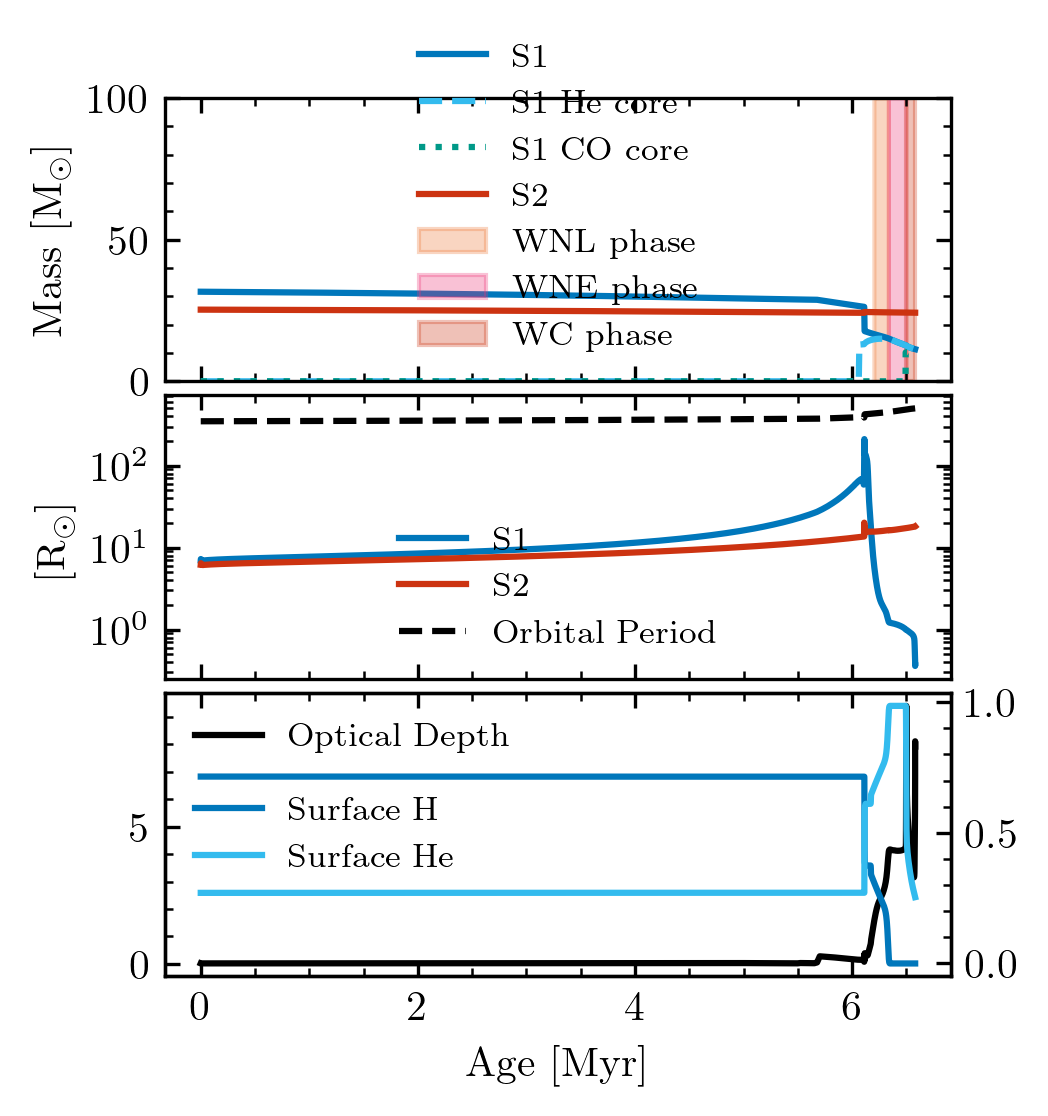

In [43]:
mask_m1 = np.isclose(grid.initial_values['star_1_mass'], 32, atol=1)
print(np.sum(mask_m1))
mask_q = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], 0.8, atol=0.025)
print(np.sum(mask_q & mask_m1))
mask_P = np.isclose(grid.initial_values['period_days'], 100, rtol=0.05)
print(np.sum(mask_P & mask_q & mask_m1))

example_index = np.where(mask_P & mask_q & mask_m1)[0][0]
model = grid[example_index]

fig, ax = plt.subplots(3, 1, figsize=(3.38, 2.535*1.5), sharex=True)

x_axis = model.binary_history['age'] / 1e6  # Convert age to Myr

ax[0].plot(x_axis, model.binary_history['star_1_mass'],
           label='S1', color=tol_vibrant[0])
ax[0].plot(x_axis, model.history1['he_core_mass'], label='S1 He core', color=tol_vibrant[1], linestyle='--')
ax[0].plot(x_axis, model.history1['co_core_mass'], label='S1 CO core', color=tol_vibrant[2], linestyle=':')
ax[0].plot(x_axis, model.binary_history['star_2_mass'],
           label='S2', color=tol_vibrant[4])

ax[1].plot(x_axis, 10**model.history1['log_R'], label='S1',
           color=tol_vibrant[0])
ax[1].plot(x_axis, 10**model.history2['log_R'], label='S2', color=tol_vibrant[4])
ax[1].plot(x_axis, model.binary_history['binary_separation'], label='Orbital Period', color='black', linestyle='--')
ax[1].set_yscale('log')

# check when WNL, WNE, WC phases occur based on surface abundances and optical depth
surface_H = model.history1['surface_h1']
surface_He = model.history1['surface_he4']
optical_depth = optical_depth_calculation(model.binary_history['star_1_mass'], 10**model.history1['log_R'], 10**model.history1['log_L'], 10**model.binary_history['lg_wind_mdot_1'], surface_H, surface_He, Teff=10**calc_Teff(model.history1['log_L'], model.history1['log_R']))


# WNL phase: surface H > 0.05, optical depth > 0.5
# not H burning
WNL_mask = (surface_H > 0.05) & (optical_depth > 1.5) & (model.history1['center_h1'] < 0.01)
if np.any(WNL_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNL_mask, color=tol_vibrant[3], alpha=0.3, label='WNL phase')
WNE_mask = (surface_H <= 0.05) & (surface_He >= 0.7) & (optical_depth > 1.5)
if np.any(WNE_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNE_mask, color=tol_vibrant[5], alpha=0.3, label='WNE phase')
WC_mask = (surface_H <= 0.05) & (surface_He < 0.7) & (optical_depth > 1.5)
if np.any(WC_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WC_mask, color=tol_vibrant[4], alpha=0.3, label='WC phase')

# twin y-axis for optical depth and abundances
ax2 = ax[2].twinx()
ax[2].plot(x_axis, optical_depth, label='Optical Depth', color='black')

ax2.plot(x_axis, surface_H, label='Surface H', color=tol_vibrant[0])
ax2.plot(x_axis, surface_He, label='Surface He', color=tol_vibrant[1])
ax2.legend()
ax[2].legend()

plt.subplots_adjust(hspace=0.05)

#ax[0].set_xticklabels([])
ax[0].set_ylim(0, 100)
#ax[0].set_xlim(0, 4)
ax[0].legend()
ax[0].set_ylabel('Mass [M$_\odot$]')
ax[1].legend()
ax[1].set_ylabel('[R$_\odot$]')
ax[-1].set_xlabel('Age [Myr]')

print(model.final_values['star_1_mass'])
print(f'WNL duration: {np.sum(np.diff(x_axis[WNL_mask])):.2f} Myr')
print(f'WNE duration: {np.sum(np.diff(x_axis[WNE_mask])):.2f} Myr')
print(f'WC duration: {np.sum(np.diff(x_axis[WC_mask])):.2f} Myr')


plt.show()


# grid slice plot 

In [13]:
def plot_grid_slice_for_q(q, ax, grid, marker_colours):
    """
    Plot a grid slice for a specific mass ratio q value.
    
    Parameters
    -----------
    q : float
        Mass ratio (M2/M1) to plot
    ax : matplotlib.axes.Axes
        Axis to plot on
    grid : PSyGrid
        The stellar evolution grid
    oneline_sel : DataFrame
        Selected population data
    metallicity : float
        Metallicity value
    marker_colours : dict
        Dictionary of colors for different markers
    """
    M1_unique = np.unique(grid.initial_values['star_1_mass'])
    
    # Select all binaries with the specified q value
    mask_out = np.isclose(M1_unique[0], grid.initial_values['star_1_mass'], atol=1e-2)
    mask_out = mask_out & np.isclose(grid.initial_values['star_2_mass'], M1_unique[0]*q, atol=1e-2)

    for M1 in M1_unique[1:]:
        mask = np.isclose(M1, grid.initial_values['star_1_mass'], atol=1e-2)
        mask = mask & (np.isclose(grid.initial_values['star_2_mass'], M1*q, atol=1e-2))
        mask_out = mask_out | mask
        
    s_marker = 5

    # Plot no MT cases
    no_MT_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'no_MT')
    if np.any(no_MT_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][no_MT_mask],
                grid.initial_values['period_days'][mask_out][no_MT_mask],
                s=s_marker,
                marker='s',
                facecolor=marker_colours['no_MT'])
        
    # Plot not converged or initial mass transfer
    not_converged_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'not_converged') | \
                         np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'initial_MT')
    if np.any(not_converged_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][not_converged_mask],
                    grid.initial_values['period_days'][mask_out][not_converged_mask],
                    s=2,
                    marker='.',
                    color=marker_colours['not_converged'],
                    linewidth=0.4, label='initial MT or not converged')
    
    # Plot unstable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'unstable_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                    grid.initial_values['period_days'][mask_out][mask_IC],
                    s=s_marker-3,
                    marker='D',
                    color=marker_colours['unstable'],
                    label='unstable MT')
    
    # Plot stable MT cases
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_MT')
    MT_cases = ['case_A', 'case_B', 'case_C', 'contact']
    for case in MT_cases:
        MT_mask = np.char.startswith(grid.final_values['termination_flag_2'][mask_out], case)
        if np.any(mask_IC & MT_mask):
            ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC & MT_mask],
                    grid.initial_values['period_days'][mask_out][mask_IC & MT_mask],
                    s=s_marker,
                    marker='s',
                    facecolor=marker_colours['stable'][case],
                    edgecolor='black',
                    lw=0.1,
                    label=case.replace('_', ' '))
            
    # Plot reverse stable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_reverse_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                grid.initial_values['period_days'][mask_out][mask_IC],
                s=s_marker-2,
                marker='o',
                color=marker_colours['reverse_stable_MT'],
                label='reverse stable MT')
            
    # Plot BBH mergers as contours
    # Z_mask = np.isclose(oneline_sel['metallicity'], metallicity, atol=1e-7)
    # q_mask = np.isclose(oneline_sel['S2_mass_i']/oneline_sel['S1_mass_i'], q, atol=1e-2)
    
    # x = np.linspace(1, 3, 201)
    # y = np.linspace(-1, 4, 201)
    # xi, yi = np.meshgrid(x[:-1], y[:-1])
    
    # h, _, _ = np.histogram2d(np.log10(oneline_sel['S1_mass_i'][Z_mask & q_mask]),
    #                          np.log10(oneline_sel['orbital_period_i'][Z_mask & q_mask]),
    #                          bins=[x, y],
    #                          density=True)
    
    #cs = ax.contour(10**xi, 10**yi, h.T, levels=[0], colors=['black'], alpha=1, zorder=20)
    # from scipy.stats import gaussian_kde
    # data = np.vstack([
    #     np.log10(oneline_sel['S1_mass_i'][Z_mask & q_mask]),
    #     np.log10(oneline_sel['orbital_period_i'][Z_mask & q_mask])
    # ])
    # kde = gaussian_kde(data, bw_method=0.085)
    # zi = kde(np.vstack([xi.flatten(), yi.flatten()]))
    # zi = zi.reshape(xi.shape)
    # ax.contour(10**xi, 10**yi, zi, levels=[kde.factor * 1], colors=['black'], alpha=1, zorder=15, linestyles='-')
    
    
    # Set plot properties
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xticks([20, 30, 50, 100, 200])
    ax.set_xticklabels(['20', '30', '50', '100', '200'])
    
    return ax

In [14]:
marker_colours = {
    'no_MT': tol_vibrant[6],
    'not_converged': 'black',
    'unstable': tol_vibrant[2],
    'stable': {
        'case_A': tol_vibrant[3],
        'case_B': tol_vibrant[4],
        'case_C': tol_vibrant[5],
        'contact': tol_vibrant[0]
    },
    'reverse_stable_MT': tol_vibrant[1]
}

In [27]:
selection = ((grid.initial_values['star_1_mass'] > 5))
mt_selection = ((grid.final_values['interpolation_class'] == 'stable_MT') 
                | (grid.final_values['interpolation_class'] == 'stable_reverse_MT')
                | (grid.final_values['interpolation_class'] == 'no_MT'))

sel_indices = np.where(selection & mt_selection)[0]
WC_durations = []
WNE_durations = []
WNL_durations = []


for i in tqdm(sel_indices):
    model = grid[i]
    surface_H = model.history1['surface_h1']
    surface_He = model.history1['surface_he4']
    optical_depth = optical_depth_calculation(model.binary_history['star_1_mass'], 10**model.history1['log_R'], 10**model.history1['log_L'], 10**model.binary_history['lg_wind_mdot_1'], surface_H, surface_He, Teff=10**calc_Teff(model.history1['log_L'], model.history1['log_R']))
    WC_mask = (surface_H <= 0.05) & (surface_He < 0.7) & (optical_depth > 1.5)
    WNE_mask = (surface_H <= 0.05) & (surface_He >= 0.7) & (optical_depth > 1.5)
    WNL_mask = (surface_H > 0.05) & (surface_H < 0.4) & (optical_depth > 1.5) & (model.history1['center_h1'] < 0.01)
    if np.any(WC_mask):
        WC_durations.append(np.sum(np.diff(model.binary_history['age'][WC_mask])) / 1e6)  # in Myr
    else:
        WC_durations.append(0)
    
    if np.any(WNE_mask):
        WNE_durations.append(np.sum(np.diff(model.binary_history['age'][WNE_mask])) / 1e6)  # in Myr
    else:
        WNE_durations.append(0)
    if np.any(WNL_mask):
        WNL_durations.append(np.sum(np.diff(model.binary_history['age'][WNL_mask])) / 1e6)  # in Myr
    else:
        WNL_durations.append(0)
    

100%|██████████| 17468/17468 [38:46<00:00,  7.51it/s] 


In [28]:
# write to files
with open('WC_durations.pkl', 'wb') as f:
    pickle.dump(WC_durations, f)
with open('WNE_durations.pkl', 'wb') as f:
    pickle.dump(WNE_durations, f)
with open('WNL_durations.pkl', 'wb') as f:
    pickle.dump(WNL_durations, f)

with open('sel_indices.pkl', 'wb') as f:
    pickle.dump(sel_indices, f)
    


In [1]:
import pickle

# read pickle files 
with open('WC_durations.pkl', 'rb') as f:
    WC_durations = pickle.load(f)
with open('WNE_durations.pkl', 'rb') as f:
    WNE_durations = pickle.load(f)
with open('WNL_durations.pkl', 'rb') as f:
    WNL_durations = pickle.load(f)
with open('sel_indices.pkl', 'rb') as f:
    sel_indices = pickle.load(f)

In [8]:
import matplotlib.pyplot as plt
from cmap import Colormap
import numpy as np

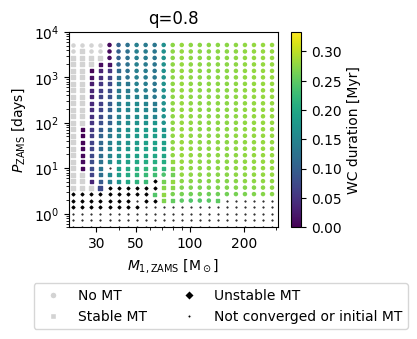

In [19]:
from tqdm import tqdm
fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))
#plot_grid_slice_for_q(0.8, ax, grid, marker_colours)

cmap = Colormap('viridis')

q_mask = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], 0.8, atol=0.025)
for ic in np.unique(grid.final_values['interpolation_class']):
    ic_mask = grid.final_values['interpolation_class'] == ic
    if 'unstable' in ic:
        marker = 'D'
        size = 2
    elif 'stable' in ic:
        marker = 's'
        continue
    elif 'no_MT' in ic:
        marker = 'o'
        continue
    else:
        marker = '.'
        size=1


    ax.scatter(grid.initial_values['star_1_mass'][ic_mask & q_mask], 
                grid.initial_values['period_days'][ic_mask & q_mask], 
                c='black',
                marker=marker,
                s=size)

IC = grid.final_values['interpolation_class'][sel_indices]
new_q_mask = np.isclose(grid.initial_values['star_2_mass'][sel_indices]/grid.initial_values['star_1_mass'][sel_indices], 0.8, atol=0.025)
for ic in np.unique(IC):
    ic_mask = IC == ic
    if 'unstable' in ic:
        marker = 'D'
    elif 'stable' in ic:
        marker = 's'
    else:
        marker = 'o'
        
    # if duration == 0.0 skip
    mask_duration = np.array(WC_durations) > 0
    
    # grey out points with zero duration
    ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                grid.initial_values['period_days'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                c='lightgrey',  
                marker=marker,
                s=5)
    
    cb = ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                grid.initial_values['period_days'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                c=np.array(WC_durations)[ic_mask & mask_duration & new_q_mask],
                marker=marker,
                cmap=cmap.to_matplotlib(),
                s=5, label=ic, vmin=0.0, vmax=np.max(WC_durations)+0.05, zorder=10)


legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='No MT', markerfacecolor='lightgrey', markersize=5),
                   plt.Line2D([0], [0], marker='s', color='w', label='Stable MT', markerfacecolor='lightgrey', markersize=5),
                   plt.Line2D([0], [0], marker='D', color='w', label='Unstable MT', markerfacecolor='black', markersize=5),
                   plt.Line2D([0], [0], marker='.', color='w', label='Not converged or initial MT', markerfacecolor='black', markersize=5)]
ax.legend(handles=legend_elements, bbox_to_anchor=(-0.2, -0.25), loc='upper left', ncol=2)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
ax.set_ylabel('$P_\mathrm{ZAMS}$ [days]')
ax.set_xlim(21, 310)
ax.set_ylim(0.5, 1e4)
ax.set_title('q=0.8')
ax.set_xticks([30, 50, 100, 200])
ax.set_xticklabels([ '30', '50', '100', '200'])
plt.colorbar(cb, label='WC duration [Myr]')

plt.savefig('grid_slice_q_0.8_WC_duration.png', dpi=300, bbox_inches='tight')

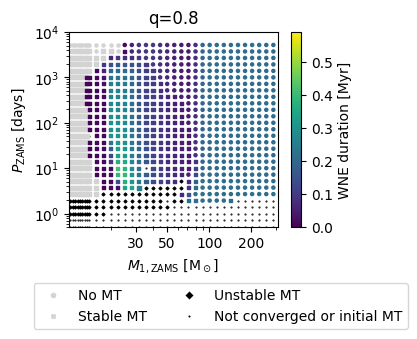

In [33]:
from tqdm import tqdm
fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))
#plot_grid_slice_for_q(0.8, ax, grid, marker_colours)

cmap = Colormap('viridis')

q_mask = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], 0.8, atol=0.025)
for ic in np.unique(grid.final_values['interpolation_class']):
    ic_mask = grid.final_values['interpolation_class'] == ic
    if 'unstable' in ic:
        marker = 'D'
        size = 2
    elif 'stable' in ic:
        marker = 's'
        continue
    elif 'no_MT' in ic:
        marker = 'o'
        continue
    else:
        marker = '.'
        size=1


    ax.scatter(grid.initial_values['star_1_mass'][ic_mask & q_mask], 
                grid.initial_values['period_days'][ic_mask & q_mask], 
                c='black',
                marker=marker,
                s=size)

IC = grid.final_values['interpolation_class'][sel_indices]
new_q_mask = np.isclose(grid.initial_values['star_2_mass'][sel_indices]/grid.initial_values['star_1_mass'][sel_indices], 0.8, atol=0.025)
for ic in np.unique(IC):
    ic_mask = IC == ic
    if 'unstable' in ic:
        marker = 'D'
    elif 'stable' in ic:
        marker = 's'
    else:
        marker = 'o'
        
    # if duration == 0.0 skip
    mask_duration = np.array(WNE_durations) > 0
    
    # grey out points with zero duration
    ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                grid.initial_values['period_days'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                c='lightgrey',  
                marker=marker,
                s=5)
    
    cb = ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                grid.initial_values['period_days'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                c=np.array(WNE_durations)[ic_mask & mask_duration & new_q_mask],
                marker=marker,
                cmap=cmap.to_matplotlib(),
                s=5, label=ic, vmin=0.0, vmax=np.max(WNE_durations)+0.05, zorder=10)


legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='No MT', markerfacecolor='lightgrey', markersize=5),
                   plt.Line2D([0], [0], marker='s', color='w', label='Stable MT', markerfacecolor='lightgrey', markersize=5),
                   plt.Line2D([0], [0], marker='D', color='w', label='Unstable MT', markerfacecolor='black', markersize=5),
                   plt.Line2D([0], [0], marker='.', color='w', label='Not converged or initial MT', markerfacecolor='black', markersize=5)]
ax.legend(handles=legend_elements, bbox_to_anchor=(-0.2, -0.25), loc='upper left', ncol=2)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
ax.set_ylabel('$P_\mathrm{ZAMS}$ [days]')
ax.set_xlim(10, 310)
ax.set_ylim(0.5, 1e4)
ax.set_title('q=0.8')
ax.set_xticks([30, 50, 100, 200])
ax.set_xticklabels([ '30', '50', '100', '200'])
plt.colorbar(cb, label='WNE duration [Myr]')

plt.savefig('grid_slice_q_0.8_WNE_duration.png', dpi=300, bbox_inches='tight')

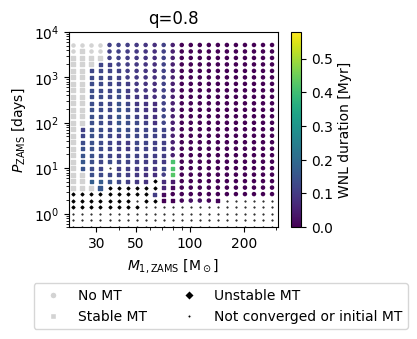

In [22]:
from tqdm import tqdm
fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))
#plot_grid_slice_for_q(0.8, ax, grid, marker_colours)

cmap = Colormap('viridis')

q_mask = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], 0.8, atol=0.025)
for ic in np.unique(grid.final_values['interpolation_class']):
    ic_mask = grid.final_values['interpolation_class'] == ic
    if 'unstable' in ic:
        marker = 'D'
        size = 2
    elif 'stable' in ic:
        marker = 's'
        continue
    elif 'no_MT' in ic:
        marker = 'o'
        continue
    else:
        marker = '.'
        size=1


    ax.scatter(grid.initial_values['star_1_mass'][ic_mask & q_mask], 
                grid.initial_values['period_days'][ic_mask & q_mask], 
                c='black',
                marker=marker,
                s=size)

IC = grid.final_values['interpolation_class'][sel_indices]
new_q_mask = np.isclose(grid.initial_values['star_2_mass'][sel_indices]/grid.initial_values['star_1_mass'][sel_indices], 0.8, atol=0.025)
for ic in np.unique(IC):
    ic_mask = IC == ic
    if 'unstable' in ic:
        marker = 'D'
    elif 'stable' in ic:
        marker = 's'
    else:
        marker = 'o'
        
    # if duration == 0.0 skip
    mask_duration = np.array(WC_durations) > 0
    
    # grey out points with zero duration
    ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                grid.initial_values['period_days'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                c='lightgrey',  
                marker=marker,
                s=5)
    
    cb = ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                grid.initial_values['period_days'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                c=np.array(WNL_durations)[ic_mask & mask_duration & new_q_mask],
                marker=marker,
                cmap=cmap.to_matplotlib(),
                s=5, label=ic, vmin=0.0, vmax=np.max(WNL_durations)+0.05, zorder=10)


legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='No MT', markerfacecolor='lightgrey', markersize=5),
                   plt.Line2D([0], [0], marker='s', color='w', label='Stable MT', markerfacecolor='lightgrey', markersize=5),
                   plt.Line2D([0], [0], marker='D', color='w', label='Unstable MT', markerfacecolor='black', markersize=5),
                   plt.Line2D([0], [0], marker='.', color='w', label='Not converged or initial MT', markerfacecolor='black', markersize=5)]
ax.legend(handles=legend_elements, bbox_to_anchor=(-0.2, -0.25), loc='upper left', ncol=2)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
ax.set_ylabel('$P_\mathrm{ZAMS}$ [days]')
ax.set_xlim(21, 310)
ax.set_ylim(0.5, 1e4)
ax.set_title('q=0.8')
ax.set_xticks([30, 50, 100, 200])
ax.set_xticklabels([ '30', '50', '100', '200'])
plt.colorbar(cb, label='WNL duration [Myr]')

plt.savefig('grid_slice_q_0.8_WNL_duration.png', dpi=300, bbox_inches='tight')

In [34]:
from tqdm import tqdm
#plot_grid_slice_for_q(0.8, ax, grid, marker_colours)

cmap = Colormap('viridis')

for q in [0.5, 0.6, 0.7, 0.8, 0.9, 0.99]:
    fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))
    q_mask = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], q, atol=0.025)
    for ic in np.unique(grid.final_values['interpolation_class']):
        ic_mask = grid.final_values['interpolation_class'] == ic
        if 'unstable' in ic:
            marker = 'D'
            size = 2
        elif 'stable' in ic:
            marker = 's'
            continue
        elif 'no_MT' in ic:
            marker = 'o'
            continue
        else:
            marker = '.'
            size=1


        ax.scatter(grid.initial_values['star_1_mass'][ic_mask & q_mask], 
                    grid.initial_values['period_days'][ic_mask & q_mask], 
                    c='black',
                    marker=marker,
                    s=size)

    IC = grid.final_values['interpolation_class'][sel_indices]
    new_q_mask = np.isclose(grid.initial_values['star_2_mass'][sel_indices]/grid.initial_values['star_1_mass'][sel_indices], q, atol=0.025)
    for ic in np.unique(IC):
        ic_mask = IC == ic
        if 'unstable' in ic:
            marker = 'D'
        elif 'stable' in ic:
            marker = 's'
        else:
            marker = 'o'
            
        # if duration == 0.0 skip
        mask_duration = np.array(WNL_durations) > 0
        
        # grey out points with zero duration
        ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                    grid.initial_values['period_days'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                    c='lightgrey',  
                    marker=marker,
                    s=5)
        
        cb = ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                    grid.initial_values['period_days'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                    c=np.array(WNL_durations)[ic_mask & mask_duration & new_q_mask],
                    marker=marker,
                    cmap=cmap.to_matplotlib(),
                    s=5, label=ic, vmin=0.0, vmax=np.max(WNL_durations)+0.05, zorder=10)


    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='No MT', markerfacecolor='lightgrey', markersize=5),
                    plt.Line2D([0], [0], marker='s', color='w', label='Stable MT', markerfacecolor='lightgrey', markersize=5),
                    plt.Line2D([0], [0], marker='D', color='w', label='Unstable MT', markerfacecolor='black', markersize=5),
                    plt.Line2D([0], [0], marker='.', color='w', label='Not converged or initial MT', markerfacecolor='black', markersize=5)]
    ax.legend(handles=legend_elements, bbox_to_anchor=(-0.2, -0.25), loc='upper left', ncol=2)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
    ax.set_ylabel('$P_\mathrm{ZAMS}$ [days]')
    ax.set_xlim(10, 310)
    ax.set_ylim(0.5, 1e4)
    ax.set_title(f'q={q:.2f}')
    ax.set_xticks([30, 50, 100, 200])
    ax.set_xticklabels([ '30', '50', '100', '200'])
    plt.colorbar(cb, label='WNL duration [Myr]')

    plt.savefig(f'grid_slice_q_{q}_WNL_duration.png', dpi=300, bbox_inches='tight')
    plt.clf()

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

In [35]:
from tqdm import tqdm
#plot_grid_slice_for_q(0.8, ax, grid, marker_colours)

cmap = Colormap('viridis')

for q in [0.5, 0.6, 0.7, 0.8, 0.9, 0.99]:
    fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))
    q_mask = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], q, atol=0.025)
    for ic in np.unique(grid.final_values['interpolation_class']):
        ic_mask = grid.final_values['interpolation_class'] == ic
        if 'unstable' in ic:
            marker = 'D'
            size = 2
        elif 'stable' in ic:
            marker = 's'
            continue
        elif 'no_MT' in ic:
            marker = 'o'
            continue
        else:
            marker = '.'
            size=1


        ax.scatter(grid.initial_values['star_1_mass'][ic_mask & q_mask], 
                    grid.initial_values['period_days'][ic_mask & q_mask], 
                    c='black',
                    marker=marker,
                    s=size)

    IC = grid.final_values['interpolation_class'][sel_indices]
    new_q_mask = np.isclose(grid.initial_values['star_2_mass'][sel_indices]/grid.initial_values['star_1_mass'][sel_indices], q, atol=0.025)
    for ic in np.unique(IC):
        ic_mask = IC == ic
        if 'unstable' in ic:
            marker = 'D'
        elif 'stable' in ic:
            marker = 's'
        else:
            marker = 'o'
            
        # if duration == 0.0 skip
        mask_duration = np.array(WNE_durations) > 0
        
        # grey out points with zero duration
        ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                    grid.initial_values['period_days'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                    c='lightgrey',  
                    marker=marker,
                    s=5)
        
        cb = ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                    grid.initial_values['period_days'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                    c=np.array(WNE_durations)[ic_mask & mask_duration & new_q_mask],
                    marker=marker,
                    cmap=cmap.to_matplotlib(),
                    s=5, label=ic, vmin=0.0, vmax=np.max(WNE_durations)+0.05, zorder=10)


    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='No MT', markerfacecolor='lightgrey', markersize=5),
                    plt.Line2D([0], [0], marker='s', color='w', label='Stable MT', markerfacecolor='lightgrey', markersize=5),
                    plt.Line2D([0], [0], marker='D', color='w', label='Unstable MT', markerfacecolor='black', markersize=5),
                    plt.Line2D([0], [0], marker='.', color='w', label='Not converged or initial MT', markerfacecolor='black', markersize=5)]
    ax.legend(handles=legend_elements, bbox_to_anchor=(-0.2, -0.25), loc='upper left', ncol=2)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
    ax.set_ylabel('$P_\mathrm{ZAMS}$ [days]')
    ax.set_xlim(10, 310)
    ax.set_ylim(0.5, 1e4)
    ax.set_title(f'q={q:.2f}')
    ax.set_xticks([30, 50, 100, 200])
    ax.set_xticklabels([ '30', '50', '100', '200'])
    plt.colorbar(cb, label='WNE duration [Myr]')

    plt.savefig(f'grid_slice_q_{q}_WNE_duration.png', dpi=300, bbox_inches='tight')
    plt.clf()

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

In [ ]:
from tqdm import tqdm
#plot_grid_slice_for_q(0.8, ax, grid, marker_colours)

cmap = Colormap('viridis')

for q in [0.5, 0.6, 0.7, 0.8, 0.9, 0.99]:
    fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))
    q_mask = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], q, atol=0.025)
    for ic in np.unique(grid.final_values['interpolation_class']):
        ic_mask = grid.final_values['interpolation_class'] == ic
        if 'unstable' in ic:
            marker = 'D'
            size = 2
        elif 'stable' in ic:
            marker = 's'
            continue
        elif 'no_MT' in ic:
            marker = 'o'
            continue
        else:
            marker = '.'
            size=1


        ax.scatter(grid.initial_values['star_1_mass'][ic_mask & q_mask], 
                    grid.initial_values['period_days'][ic_mask & q_mask], 
                    c='black',
                    marker=marker,
                    s=size)

    IC = grid.final_values['interpolation_class'][sel_indices]
    new_q_mask = np.isclose(grid.initial_values['star_2_mass'][sel_indices]/grid.initial_values['star_1_mass'][sel_indices], q, atol=0.025)
    for ic in np.unique(IC):
        ic_mask = IC == ic
        if 'unstable' in ic:
            marker = 'D'
        elif 'stable' in ic:
            marker = 's'
        else:
            marker = 'o'
            
        # if duration == 0.0 skip
        mask_duration = np.array(WC_durations) > 0
        
        # grey out points with zero duration
        ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                    grid.initial_values['period_days'][sel_indices][ic_mask & ~mask_duration & new_q_mask], 
                    c='lightgrey',  
                    marker=marker,
                    s=5)
        
        cb = ax.scatter(grid.initial_values['star_1_mass'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                    grid.initial_values['period_days'][sel_indices][ic_mask & mask_duration & new_q_mask], 
                    c=np.array(WC_durations)[ic_mask & mask_duration & new_q_mask],
                    marker=marker,
                    cmap=cmap.to_matplotlib(),
                    s=5, label=ic, vmin=0.0, vmax=np.max(WC_durations)+0.05, zorder=10)

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='No MT', markerfacecolor='lightgrey', markersize=5),
                    plt.Line2D([0], [0], marker='s', color='w', label='Stable MT', markerfacecolor='lightgrey', markersize=5),
                    plt.Line2D([0], [0], marker='D', color='w', label='Unstable MT', markerfacecolor='black', markersize=5),
                    plt.Line2D([0], [0], marker='.', color='w', label='Not converged or initial MT', markerfacecolor='black', markersize=5)]
    ax.legend(handles=legend_elements, bbox_to_anchor=(-0.2, -0.25), loc='upper left', ncol=2)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
    ax.set_ylabel('$P_\mathrm{ZAMS}$ [days]')
    ax.set_xlim(21, 310)
    ax.set_ylim(0.5, 1e4)
    ax.set_title(f'q={q:.2f}')
    ax.set_xticks([30, 50, 100, 200])
    ax.set_xticklabels([ '30', '50', '100', '200'])
    plt.colorbar(cb, label='WC duration [Myr]')

    plt.savefig(f'grid_slice_q_{q}_WC_duration.png', dpi=300, bbox_inches='tight')
    plt.clf()

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>

<Figure size 338x253.5 with 0 Axes>